# APTOS 2019 | Curadoria e pré-processamento de retinografias para CNNs
**Notebook de pesquisa • execução no Google Colab • versão 1.0**

Objetivo: produzir um conjunto rastreável de imagens RGB com geometria preservada, contraste controlado, rótulos válidos e separação de dados auditável. O notebook não treina uma rede nem promete qualidade clínica. Ele entrega manifestos, relatórios, imagens PNG e lotes PyTorch prontos para a próxima etapa.

**Fluxo:** aquisição → catálogo → integridade → avaliação de qualidade → duplicatas → grupos → divisão → geometria → fotometria → normalização → aumento no treino → exportação → testes de entrada.

A proposta é uma síntese própria, não a reprodução de um artigo. A planilha fornecida contém 22 registros preenchidos; nem todos descrevem pré-processamento. O artigo EdgeRetina é uma referência de baixo custo, não de máxima qualidade. As referências e as escolhas de engenharia estão identificadas na seção final. O dataset original nunca é alterado.

### Como executar
1. Envie `APTOS.zip` ao Google Drive em `Meu Drive/datasets/` (não repita se já estiver lá). Abra este `.ipynb` no Colab.
2. Execute as células em ordem. A extração e o processamento usam o disco local. Não há `files.upload()` para o ZIP.
3. Revise as tabelas de qualidade e duplicatas. Se necessário, edite os CSVs de decisões no Drive e execute novamente a partir da seção 7.
4. A última seção testa os dados e cria um ZIP opcional de entrega. GPU não é necessária para a curadoria. Reserve espaço no disco para as imagens originais e processadas.

**Política de segurança experimental:** por padrão, o teste de origem fica reservado, mesmo se tiver rótulos. Reorganizamos apenas treino e validação. Uma nova divisão 70/15/15 só é permitida se o teste de origem for uma divisão interna rotulada e você autorizar explicitamente. O teste oficial sem rótulos nunca deve ser incorporado ao desenvolvimento.

## 1. Configuração e dependências
Os valores abaixo são pontos de partida conservadores, não limiares clínicos validados. Fixe-os antes de avaliar o teste. A resolução de 768 pixels prioriza detalhes; mude para a resolução exigida pela CNN e compare 518/768 em validação. Não há necessidade de potência de dois para a maioria das CNNs, mas verifique a arquitetura.

In [ ]:
import os, json, hashlib, zipfile, shutil, stat, random, math, csv, platform
from pathlib import Path, PurePosixPath
from collections import defaultdict
import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageOps, ImageFile
from scipy.ndimage import distance_transform_edt
from sklearn.model_selection import GroupShuffleSplit
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ImageFile.LOAD_TRUNCATED_IMAGES = False
ORIGEM = 'drive'  # 'local' se o ZIP já estiver no ambiente
ZIP_DRIVE = '/content/drive/MyDrive/datasets/APTOS.zip'
ZIP_LOCAL = '/content/APTOS.zip'
TRABALHO = Path('/content/aptos_cnn')
RELATORIOS = Path('/content/drive/MyDrive/datasets/APTOS_CNN_relatorios')
# Para execução local sem Drive, altere RELATORIOS para um caminho local.
COLUNA_ID = None; COLUNA_ROTULO = None; COLUNA_PACIENTE = None
TESTE_ROTULADO = 'auto'  # 'auto', True, False; False ignora rótulos fictícios
MODO_SPLIT = 'preservar_teste'  # ou 'novo_70_15_15'
AUTORIZAR_REDIVISAO_TESTE = False
FRACAO_VAL_DEV = 0.17647  # 15/(70+15), se o teste reservado for 15% do total
IMG_SIZE = 768
RES_QUALIDADE = 512
LIMIAR_FOV = 12  # intensidade máxima RGB em 8 bits
MARGEM_FOV = 0.03
MIN_LADO = 64  # rejeição técnica, não garantia de qualidade
PHASH_MAX = 6  # Hamming, 64 bits; candidatos, não prova de identidade
FOCO_ALERTA = 30.0  # apenas triagem na escala de referência
AREA_ALERTA = 0.25
EXPOSICAO_ALERTA = 0.20
REALCE = 'clahe_lab'  # 'none' para controle de ablação
CLAHE_CLIP = 2.0; CLAHE_GRID = (8,8); CLAHE_MISTURA = 0.5
DENOISE = False  # bilateral leve opcional, desativado para preservar microlesões
NORMALIZACAO = 'imagenet'  # 'train' ou 'zero_um'; adapte ao backbone
BATCH_SIZE = 4; NUM_WORKERS = 0
AUGMENT = True; FLIP = True; BRILHO = 0.08; CONTRASTE = 0.08
EXIGIR_REVISAO_QUALIDADE = False  # True exige decisão explícita para alertas de desenvolvimento
EXPORTAR_ZIP = False
EXTENSOES = {'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
TRABALHO.mkdir(parents=True, exist_ok=True)
assert MODO_SPLIT in ('preservar_teste','novo_70_15_15')
assert REALCE in ('none','clahe_lab') and NORMALIZACAO in ('imagenet','train','zero_um')
assert 0 <= CLAHE_MISTURA <= 1 and IMG_SIZE >= 128
print('Python:', platform.python_version(), '| OpenCV:',cv2.__version__, '| PyTorch:',torch.__version__)

Python: 3.13.18 | OpenCV: 5.0.0 | PyTorch: 2.14.1+cpu


## 2. Aquisição do ZIP
A montagem do Drive evita o upload grande pelo navegador do Colab. A extração é retomada apenas quando existe um marcador de conclusão para o mesmo arquivo. O código anterior de DRStageNet foi reaproveitado para localizar as pastas aninhadas, como `train_images/train_images`. O ZIP não é modificado.

In [ ]:
if ORIGEM == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    ZIP = Path(ZIP_DRIVE)
elif ORIGEM == "local":
    ZIP = Path(ZIP_LOCAL)
else:
    raise ValueError("ORIGEM deve ser drive ou local.")
if not ZIP.is_file():
    raise FileNotFoundError(f"ZIP não encontrado: {ZIP}. Confira a configuração.")
if not zipfile.is_zipfile(ZIP):
    raise ValueError(f"ZIP inválido: {ZIP}")
print(f"Arquivo: {ZIP} | {ZIP.stat().st_size / 1024**2:.1f} MiB")
RELATORIOS.mkdir(parents=True, exist_ok=True)
print('Relatórios:', RELATORIOS)

Mounted at /content/drive
Arquivo: /content/drive/MyDrive/datasets/APTOS.zip | 8204.0 MiB
Relatórios: /content/drive/MyDrive/datasets/APTOS_CNN_relatorios


In [ ]:
import stat as statmod
DIVISOES = {"treino": ("train_1.csv", "train_images"),
            "validacao": ("valid.csv", "val_images"),
            "teste": ("test.csv", "test_images")}

def extrair_zip(arquivo, destino):
    with zipfile.ZipFile(arquivo) as z:
        itens = z.infolist()
        if sum(i.file_size for i in itens) > shutil.disk_usage(destino).free:
            raise OSError("Espaço insuficiente para extrair o dataset.")
        vistos = set()
        for item in tqdm(itens, desc="Extraindo arquivos", unit="arquivo"):
            p = PurePosixPath(item.filename.replace("\\", "/"))
            if p.is_absolute() or ".." in p.parts or any(":" in s for s in p.parts):
                raise ValueError(f"Caminho inválido: {item.filename}")
            if statmod.S_ISLNK(item.external_attr >> 16):
                raise ValueError(f"Link simbólico no ZIP: {item.filename}")
            alvo = destino.joinpath(*p.parts)
            if not item.is_dir() and alvo in vistos:
                raise ValueError(f"Entrada duplicada no ZIP: {item.filename}")
            if not item.is_dir(): vistos.add(alvo)
            if item.is_dir():
                alvo.mkdir(parents=True, exist_ok=True)
            else:
                alvo.parent.mkdir(parents=True, exist_ok=True)
                with z.open(item) as entrada, alvo.open("wb") as saida:
                    shutil.copyfileobj(entrada, saida, length=1024**2)

def localizar_unico(base, nome, pasta=False):
    candidatos = [p for p in base.rglob("*") if p.name.lower() == nome.lower()
                  and (p.is_dir() if pasta else p.is_file())
                  and "__MACOSX" not in p.parts]
    if pasta and len(candidatos) > 1:
        diretos = [p for p in candidatos if any(f.is_file() and f.suffix.lower() in EXTENSOES for f in p.iterdir())]
        if diretos:
            candidatos = diretos
        else:
            # Se só houver subpastas por classe, escolhe o candidato mais interno.
            candidatos = [p for p in candidatos if not any(p in q.parents for q in candidatos if q != p)]
    if len(candidatos) != 1:
        raise ValueError(f"Esperado um item {nome}; encontrados: {candidatos}")
    return candidatos[0]

# Identifica uma extração completa na sessão por caminho, tamanho e modificação do ZIP.
stat = ZIP.stat()
chave = hashlib.sha256(f"{ZIP.resolve()}|{stat.st_size}|{stat.st_mtime_ns}".encode()).hexdigest()[:16]
DATASET_DIR = TRABALHO / f"extraido_{chave}"
MARCADOR = DATASET_DIR / ".extracao_concluida"
if not MARCADOR.exists():
    if DATASET_DIR.exists():
        shutil.rmtree(DATASET_DIR)  # remove somente extração incompleta deste ZIP
    DATASET_DIR.mkdir()
    extrair_zip(ZIP, DATASET_DIR)
    MARCADOR.touch()
else:
    print("Reaproveitando extração concluída.")
CAMINHOS = {nome: (localizar_unico(DATASET_DIR, csv), localizar_unico(DATASET_DIR, pasta, True))
            for nome, (csv, pasta) in DIVISOES.items()}
for nome, (csv, pasta) in CAMINHOS.items():
    print(nome, "|", csv.name, "|", pasta)
# Isola decisões por versão do ZIP, para evitar reutilizar revisões de outro dataset.
RELATORIOS = RELATORIOS / chave
RELATORIOS.mkdir(parents=True, exist_ok=True)
print("Relatórios desta versão:", RELATORIOS)

Extraindo arquivos:   0%|          | 0/3665 [00:00<?, ?arquivo/s]

treino | train_1.csv | /content/aptos_cnn/extraido_c26fc7e4d3d6b2c6/train_images/train_images
validacao | valid.csv | /content/aptos_cnn/extraido_c26fc7e4d3d6b2c6/val_images/val_images
teste | test.csv | /content/aptos_cnn/extraido_c26fc7e4d3d6b2c6/test_images/test_images
Relatórios desta versão: /content/drive/MyDrive/datasets/APTOS_CNN_relatorios/c26fc7e4d3d6b2c6


## 3. Catálogo e validação de metadados
O APTOS é um problema ordinal de cinco classes (0 a 4). O catálogo preserva os graus originais, os identificadores, a origem e o caminho. Arquivos sem rótulo no teste reservado são aceitos. Arquivos ausentes, nomes ambíguos, rótulos inválidos e imagens não catalogadas são registrados. Não inferimos pacientes a partir do nome sem evidência. Caso exista uma coluna de paciente, informe-a explicitamente se não for reconhecida. Os arquivos não catalogados ficam fora do treinamento.

In [ ]:
IDS = ('id_code','image_id','image name','image_name','id','image','images','filename','file_name','arquivo','path','image_path')
ROTULOS = ('diagnosis','label','labels','grade','level','class','target','codigo_diagnostico','severity','dr_grade','retinopathy_grade','diagnostic')
PACIENTES = ('patient_id','patient','id_patient','patientid','id_paciente','paciente')
def coluna(df, preferida, alternativas):
    mapa = {str(x).strip().lower(): x for x in df.columns}
    if preferida is not None:
        if preferida.lower() not in mapa: raise ValueError(f'Coluna {preferida} ausente: {list(df.columns)}')
        return mapa[preferida.lower()]
    return next((mapa[x] for x in alternativas if x in mapa), None)

def ler_catalogo(caminhos):
    registros, orfas = [], []
    for origem,(arquivo,pasta) in caminhos.items():
        header=arquivo.open(encoding='utf-8-sig').readline()
        sep=';' if ';' in header and ',' not in header else ('\t' if '\t' in header and ',' not in header else ',')
        df=pd.read_csv(arquivo,sep=sep,dtype=str,encoding='utf-8-sig')
        df.columns=df.columns.str.strip()
        ci=coluna(df,COLUNA_ID,IDS)
        cy=None if origem=="teste" and TESTE_ROTULADO is False else coluna(df,COLUNA_ROTULO,ROTULOS)
        cp=coluna(df,COLUNA_PACIENTE,PACIENTES)
        if ci is None: raise ValueError(f'{arquivo.name}: ID não reconhecido: {list(df.columns)}')
        if origem=='teste' and TESTE_ROTULADO is False: cy=None
        if cy is None and (origem!='teste' or TESTE_ROTULADO is True): raise ValueError(f'{arquivo.name}: rótulo ausente.')
        nomes, stems = defaultdict(list), defaultdict(list)
        imgs=sorted(p for p in pasta.rglob('*') if p.is_file() and p.suffix.lower() in EXTENSOES and '__MACOSX' not in p.parts)
        for p in imgs: nomes[p.name.casefold()].append(p); stems[p.stem.casefold()].append(p)
        usados=set()
        for i,r in df.iterrows():
            ident=str(r[ci]).strip() if pd.notna(r[ci]) else ''
            basename=PurePosixPath(ident.replace('\\','/')).name
            opcoes=nomes[basename.casefold()] if Path(basename).suffix.lower() in EXTENSOES else stems[basename.casefold()]
            y=pd.to_numeric(r[cy],errors='coerce') if cy else np.nan
            motivo=[]
            if not ident: motivo.append('id_ausente')
            if len(opcoes)!=1: motivo.append('arquivo_ausente' if not opcoes else 'nome_ambiguo')
            if cy and y not in range(5): motivo.append('rotulo_invalido')
            p=opcoes[0] if len(opcoes)==1 else None
            if p: usados.add(p)
            registros.append(dict(uid=f'{origem}_{i:06d}',id_code=Path(basename).stem,origem=origem,
                caminho=str(p) if p else '',diagnosis=int(y) if y in range(5) else np.nan,
                paciente=str(r[cp]).strip() if cp and pd.notna(r[cp]) else '',motivo=';'.join(motivo)))
        orfas.extend(dict(origem=origem,caminho=str(p)) for p in imgs if p not in usados)
        print(origem, len(df), 'linhas |',len(imgs),'arquivos | colunas:',ci,cy,cp)
    return pd.DataFrame(registros),pd.DataFrame(orfas,columns=['origem','caminho'])

catalogo, orfas=ler_catalogo(CAMINHOS)
catalogo.to_csv(RELATORIOS/'catalogo_original.csv',index=False)
orfas.to_csv(RELATORIOS/'arquivos_sem_metadados.csv',index=False)
assert catalogo.uid.is_unique
print('Linhas inválidas:',catalogo.motivo.ne('').sum(),'| Sem metadados:',len(orfas))
display(pd.crosstab(catalogo.diagnosis,catalogo.origem))

treino 2930 linhas | 2930 arquivos | colunas: id_code diagnosis None
validacao 366 linhas | 366 arquivos | colunas: id_code diagnosis None
teste 366 linhas | 366 arquivos | colunas: id_code diagnosis None
Linhas inválidas: 0 | Sem metadados: 0


origem,teste,treino,validacao
diagnosis,,,
0,199,1434,172
1,30,300,40
2,87,808,104
3,17,154,22
4,33,234,28


## 4. Geometria do campo de visão (FOV)
Em vez de remover somente colunas inteiramente pretas, estimamos o contorno da maior região iluminada numa miniatura. A máscara é usada para localizar o campo retiniano e calcular métricas de qualidade, **não para apagar pixels** da fotografia. A caixa delimitadora recebe margem de 3%; se a estimativa for incerta ou o recorte descartar mais de 0,5% dos pixels acima do limiar de intensidade, mantemos a imagem inteira. Esse indicador não comprova preservação de lesões. O método pode falhar com reflexos ou iluminação extrema; os indicadores e a visualização permitem revisão.

O recorte centraliza aproximadamente o campo visível, não o disco óptico. O padding preto simétrico e a interpolação Lanczos com antialiasing mantêm a escala isotrópica. Lanczos é uma escolha de engenharia para redução; pode gerar ringing em bordas muito fortes. A resolução final não recupera detalhes ausentes. A máscara binária usa vizinho mais próximo. Nenhuma região é reconstruída.

In [ ]:
def carregar_rgb(caminho):
    with Image.open(caminho) as im:
        im.verify()  # checa estrutura
    with Image.open(caminho) as im:
        im.load()  # força decodificação; detecta parte dos truncamentos
        return np.array(ImageOps.exif_transpose(im).convert('RGB'))

def fov(rgb):
    h,w=rgb.shape[:2]; escala=min(1,512/max(h,w))
    sw,sh=max(1,round(w*escala)),max(1,round(h*escala))
    mini=cv2.resize(rgb,(sw,sh),interpolation=cv2.INTER_AREA)
    binaria=(mini.max(axis=2)>LIMIAR_FOV).astype(np.uint8)
    k=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))
    limpa=cv2.morphologyEx(binaria,cv2.MORPH_CLOSE,k)
    limpa=cv2.morphologyEx(limpa,cv2.MORPH_OPEN,k)
    contornos,_=cv2.findContours(limpa,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    mascara=np.zeros((sh,sw),np.uint8)
    if not contornos:
        return (0,0,w,h),mascara,0.,1.,True
    maior=max(contornos,key=cv2.contourArea)
    cv2.drawContours(mascara,[maior],-1,1,cv2.FILLED)
    x,y,bw,bh=cv2.boundingRect(maior)
    area=float(mascara.mean())
    cobertura=float((mascara*binaria).sum()/max(1,binaria.sum()))
    dx=(x+bw/2-sw/2)/sw; dy=(y+bh/2-sh/2)/sh
    desloc=float(np.hypot(dx,dy))
    incerto=area<0.10 or cobertura<0.94 or min(bw,bh)<16
    margem=math.ceil(MARGEM_FOV*max(bw,bh))
    # Expande a caixa em coordenadas originais; evita corte por arredondamento.
    caixa=(max(0,math.floor((x-margem)*w/sw)),max(0,math.floor((y-margem)*h/sh)),
           min(w,math.ceil((x+bw+margem)*w/sw)),min(h,math.ceil((y+bh+margem)*h/sh)))
    # Checagem adicional na imagem original: não perder mais de 0,5% dos
    # pixels acima do limiar. É um indicador de retenção, não máscara clínica.
    sinal=rgb.max(axis=2)>LIMIAR_FOV
    x0,y0,x1,y1=caixa
    total=int(sinal.sum())
    if total and sinal[y0:y1,x0:x1].sum()/total<.995: incerto=True
    if incerto: caixa=(0,0,w,h)
    return caixa,mascara,area,desloc,incerto

def geometria(rgb,tamanho=IMG_SIZE):
    h,w=rgb.shape[:2]; caixa,m,area,desloc,incerto=fov(rgb)
    x0,y0,x1,y1=caixa; rec=rgb[y0:y1,x0:x1]
    mask=cv2.resize(m,(w,h),interpolation=cv2.INTER_NEAREST)[y0:y1,x0:x1]
    rh,rw=rec.shape[:2]; lado=max(rh,rw)
    top=(lado-rh)//2; bottom=lado-rh-top; left=(lado-rw)//2; right=lado-rw-left
    quadrado=np.pad(rec,((top,bottom),(left,right),(0,0)))
    mask=np.pad(mask,((top,bottom),(left,right)))
    final=np.array(Image.fromarray(quadrado).resize((tamanho,tamanho),Image.Resampling.LANCZOS))
    mask=cv2.resize(mask,(tamanho,tamanho),interpolation=cv2.INTER_NEAREST).astype(bool)
    sinal=rgb.max(axis=2)>LIMIAR_FOV
    retencao=float(sinal[y0:y1,x0:x1].sum()/max(1,sinal.sum()))
    assert quadrado.shape[:2]==(lado,lado)
    assert np.array_equal(quadrado[top:top+rh,left:left+rw],rec)
    assert abs(left-right)<=1 and abs(top-bottom)<=1
    return final,mask,dict(caixa=caixa,padding=(left,top,right,bottom),lado=lado,area=area,desloc=desloc,incerto=incerto,retencao=retencao)

## 5. Auditoria de integridade, foco, exposição e duplicatas exatas
A variância do Laplaciano mede a energia das variações de intensidade de segunda ordem. É calculada no canal verde, dentro do FOV erodido e na mesma resolução, para evitar que a borda preta domine a medida. Um valor baixo sinaliza possível desfoque; não prova que a imagem é inadequada. Exposição é avaliada pela fração de pixels quase pretos ou com pelo menos um canal saturado na região interna. A área do FOV e a descentralização ajudam a identificar aquisições problemáticas. EyeQ e QuickQual inspiram a separação de qualidade e diagnóstico; **este notebook usa métricas heurísticas, não executa os modelos EyeQ/QuickQual**.

SHA-256 de bytes detecta arquivos idênticos. O hash dos pixels RGB inclui as dimensões e identifica imagens decodificadas idênticas, independentemente de metadados. pHash de 64 bits resume frequências espaciais baixas da retinografia em escala de cinza; armazenamos também a versão espelhada para detectar candidatos invertidos. Não é uma prova de identidade.

Rejeições automáticas: metadados inválidos, falha de decodificação, dimensão inferior ao mínimo técnico imagem sem sinal acima do limiar ou imagem praticamente uniforme (desvio padrão RGB ≤ 1 por canal). Foco e exposição ruins são **alertas**. A inspeção humana evita excluir preferencialmente graus mais graves. Para o teste reservado, as regras são fixas e os problemas são relatados; não se ajustam limites com base em seu desempenho.

In [ ]:
def hash_arquivo(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(1024**2),b''): h.update(b)
    return h.hexdigest()

def phash(rgb):
    gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
    a=cv2.resize(gray,(32,32),interpolation=cv2.INTER_AREA).astype(np.float32)
    d=cv2.dct(a)[:8,:8].ravel(); med=np.median(d[1:]); bits=(d>med); bits[0]=False
    return np.packbits(bits).tobytes().hex()

def auditar_um(r):
    out=dict(uid=r.uid,sha_arquivo='',sha_pixels='',phash='',phash_flip='',largura=np.nan,altura=np.nan,
             foco=np.nan,escuros=np.nan,saturados=np.nan,area_fov=np.nan,deslocamento=np.nan,alertas='',erro='')
    if r.motivo: out['erro']=r.motivo; return out
    try:
        rgb=carregar_rgb(r.caminho); h,w=rgb.shape[:2]
        out.update(largura=w,altura=h,sha_arquivo=hash_arquivo(r.caminho))
        hh=hashlib.sha256(str(rgb.shape).encode()); hh.update(rgb.tobytes()); out['sha_pixels']=hh.hexdigest()
        if min(h,w)<MIN_LADO: out['erro']='dimensao_insuficiente'; return out
        if rgb.max()<=LIMIAR_FOV: out['erro']='imagem_sem_sinal'; return out
        if np.max(rgb.reshape(-1,3).std(axis=0))<=1: out['erro']='imagem_uniforme'; return out
        mini,mask,geo=geometria(rgb,RES_QUALIDADE)
        out.update(phash=phash(mini),phash_flip=phash(np.ascontiguousarray(mini[:,::-1])),area_fov=geo['area'],deslocamento=geo['desloc'])
        interior=cv2.erode(mask.astype(np.uint8),np.ones((15,15),np.uint8)).astype(bool)
        alertas=[]
        if interior.sum()>100:
            lap=cv2.Laplacian(mini[:,:,1],cv2.CV_32F)
            out['foco']=float(lap[interior].var())
            out['escuros']=float((mini[interior].max(axis=1)<=15).mean())
            out['saturados']=float((mini[interior].max(axis=1)>=250).mean())
            if out['foco']<FOCO_ALERTA: alertas.append('possivel_desfoque')
            if max(out['escuros'],out['saturados'])>EXPOSICAO_ALERTA: alertas.append('exposicao')
        else: alertas.append('fov_interno_insuficiente')
        if geo['incerto'] or geo['area']<AREA_ALERTA: alertas.append('fov_revisar')
        if geo['desloc']>0.15: alertas.append('descentralizada')
        out['alertas']=';'.join(alertas)
    except Exception as e:
        out['erro']='falha_leitura_ou_auditoria: '+str(e)[:250]
    return out

aud=pd.DataFrame([auditar_um(r) for r in tqdm(catalogo.itertuples(index=False),total=len(catalogo),desc='Integridade e qualidade')])
auditoria=catalogo.merge(aud,on='uid',validate='one_to_one')
auditoria.to_csv(RELATORIOS/'auditoria_integridade_qualidade.csv',index=False)
print('Rejeições técnicas:',auditoria.erro.ne('').sum(),'| Alertas:',auditoria.alertas.ne('').sum())
display(auditoria.groupby('origem').agg(total=('uid','size'),foco_mediano=('foco','median'),area_mediana=('area_fov','median')))

Integridade e qualidade:   0%|          | 0/3662 [00:00<?, ?it/s]

Rejeições técnicas: 0 | Alertas: 1664


,total,foco_mediano,area_mediana
origem,,,
teste,366,34.377596,0.796700
treino,2930,34.166676,0.796568
validacao,366,31.565750,0.796740


## 6. Duplicatas perceptuais e agrupamento anti-vazamento
A distância de Hamming conta bits diferentes entre dois hashes. A busca exaustiva em blocos compara cada par, inclusive com espelhamento. O limiar inicial 6/64 é uma escolha conservadora de triagem. A distância não detecta todas as mudanças de enquadramento, rotações ou capturas do mesmo paciente. Retinas diferentes podem ter hashes próximos. Por isso, **não excluímos automaticamente candidatos perceptuais**. Eles ficam juntos na mesma divisão, mesmo se houver falsos positivos, salvo decisão humana explícita de que o par é diferente. O agrupamento é transitivo. Grupos grandes merecem inspeção.

O relatório apresenta pares, distância e indicação de espelhamento; a revisão mostra as fotografias lado a lado. Para escala maior que APTOS, a busca quadrática deve ser substituída por índice de hashes. Não usamos embeddings de um modelo treinado no próprio dataset.

In [ ]:
validos=auditoria[auditoria.erro.eq('')].copy().reset_index(drop=True)
if validos.empty: raise ValueError('Nenhuma imagem tecnicamente válida.')
# Comparação vetorizada, limitada a blocos de 128 linhas.
LUT=np.array([i.bit_count() for i in range(256)],dtype=np.uint8)
H=np.array([list(bytes.fromhex(x)) for x in validos.phash],dtype=np.uint8)
F=np.array([list(bytes.fromhex(x)) for x in validos.phash_flip],dtype=np.uint8)
pares=[]
for inicio in tqdm(range(0,len(H),128),desc='Busca perceptual'):
    fim=min(inicio+128,len(H))
    d1=LUT[np.bitwise_xor(H[inicio:fim,None,:],H[None,:,:])].sum(axis=2)
    d2=LUT[np.bitwise_xor(H[inicio:fim,None,:],F[None,:,:])].sum(axis=2)
    d=np.minimum(d1,d2)
    a,b=np.where((d<=PHASH_MAX)&(np.arange(inicio,fim)[:,None]<np.arange(len(H))[None,:]))
    for i,j in zip(a,b):
        u,v=validos.iloc[inicio+i],validos.iloc[j]
        if u.sha_pixels==v.sha_pixels: continue
        pares.append(dict(uid_a=u.uid,uid_b=v.uid,distancia=int(d[i,j]),espelhado=bool(d2[i,j]<d1[i,j]),
            origem_a=u.origem,origem_b=v.origem,grau_a=u.diagnosis,grau_b=v.diagnosis))
PARES_COL=['uid_a','uid_b','distancia','espelhado','origem_a','origem_b','grau_a','grau_b']
pares=pd.DataFrame(pares,columns=PARES_COL).sort_values(['distancia','uid_a','uid_b'])
pares.to_csv(RELATORIOS/'candidatos_perceptuais.csv',index=False)
print('Pares perceptuais:',len(pares))
display(pares.head(15))
# Relatório de grupos exatos, incluindo rótulos divergentes.
exatas=validos[validos.sha_pixels.duplicated(False)|validos.sha_arquivo.duplicated(False)].sort_values('sha_pixels')
exatas.to_csv(RELATORIOS/'duplicatas_exatas.csv',index=False)
print('Imagens em grupos exatos:',len(exatas))

Busca perceptual:   0%|          | 0/29 [00:00<?, ?it/s]

Pares perceptuais: 17641


,uid_a,uid_b,distancia,espelhado,origem_a,origem_b,grau_a,grau_b
17524,teste_000087,teste_000217,0,False,teste,teste,4,2
50,treino_000004,treino_001472,0,False,treino,treino,0,0
127,treino_000007,validacao_000138,0,False,treino,validacao,0,0
1469,treino_000136,treino_000406,0,False,treino,treino,2,2
1900,treino_000183,treino_000922,0,False,treino,treino,0,0
2141,treino_000209,treino_001425,0,False,treino,treino,0,0
2152,treino_000209,treino_002195,0,False,treino,treino,0,0
2250,treino_000229,treino_000762,0,False,treino,treino,2,0
2253,treino_000229,treino_000992,0,False,treino,treino,2,4
2272,treino_000229,treino_001943,0,False,treino,treino,2,2


Imagens em grupos exatos: 251


## 7. Revisão visual e decisões rastreáveis
As miniaturas abaixo são de desenvolvimento (treino e validação de origem). Não utilize exemplos do teste reservado para ajustar qualidade ou realce. O notebook gera dois arquivos editáveis, sem sobrescrever decisões já salvas:

- `decisoes_qualidade.csv`: preencha `decisao` com `manter` ou `rejeitar` e escreva o motivo. Para exigir revisão de todos os alertas de desenvolvimento, ative `EXIGIR_REVISAO_QUALIDADE`.
- `decisoes_pares.csv`: preencha `decisao` com `diferentes`, `duplicata` ou deixe vazio. `diferentes` remove a ligação perceptual; `duplicata` confirma a identidade e permite remover a cópia. Não altere decisões de pares envolvendo teste reservado sem protocolo previamente aprovado. Pares não revisados permanecem agrupados.

As exclusões não apagam arquivos. Para continuar sem revisão manual, o padrão mantém imagens suspeitas de qualidade e agrupa pares não revisados. Isso evita exclusão indevida, mas não garante ausência de desfoque. Antes de um experimento definitivo, revise as candidatas. A avaliação do teste deve incluir o número de amostras rejeitadas e suas razões.

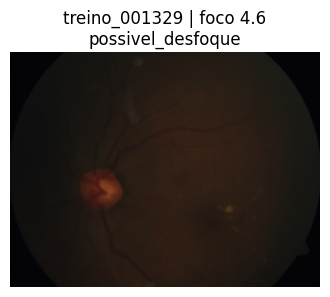

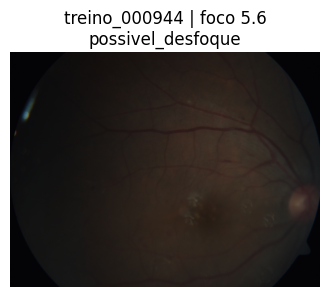

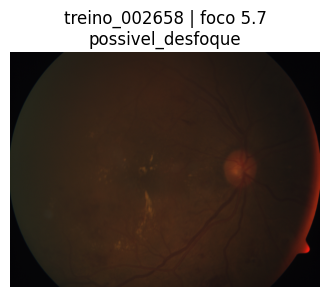

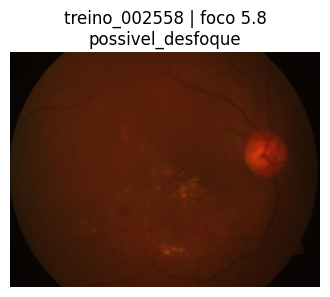

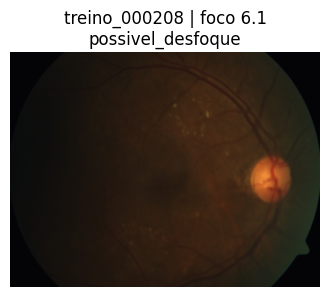

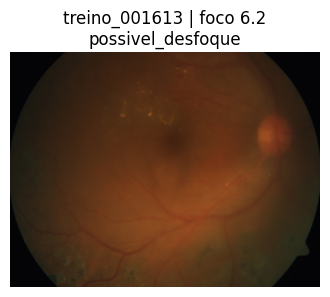

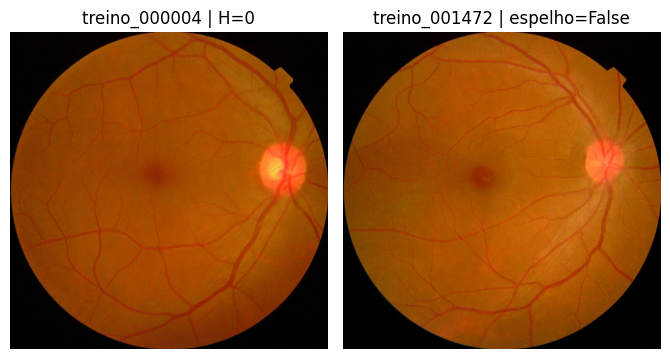

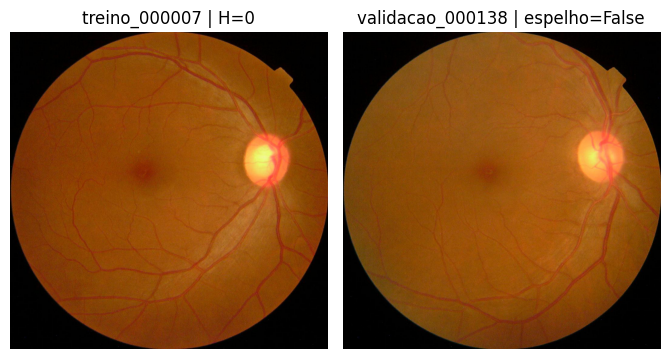

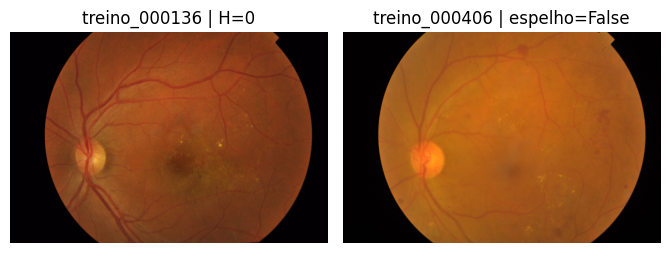

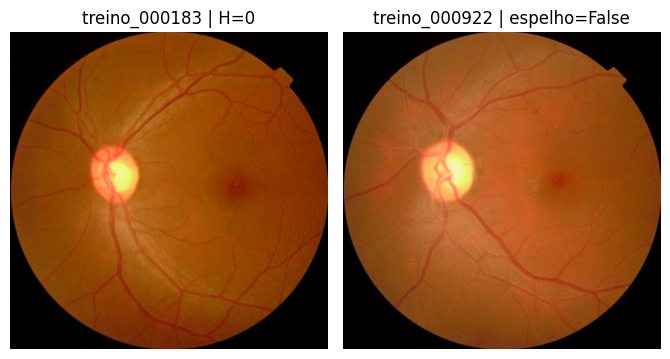

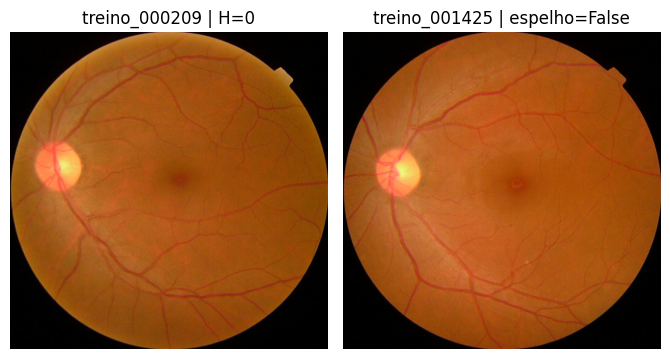

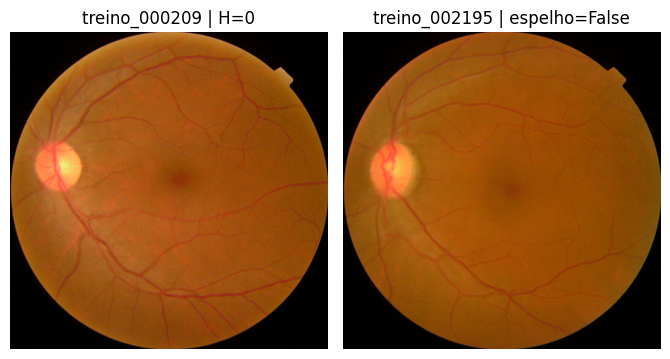

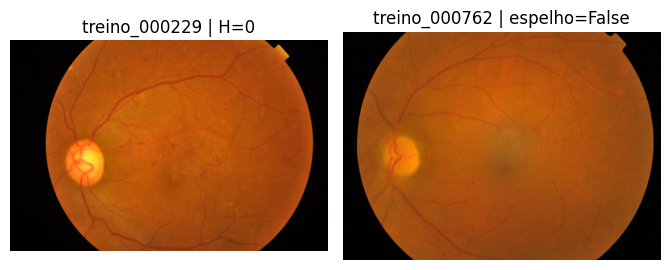

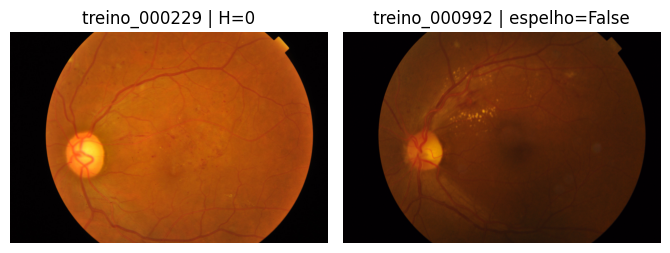

Edite os CSVs no Drive, se necessário: /content/drive/MyDrive/datasets/APTOS_CNN_relatorios/c26fc7e4d3d6b2c6/decisoes_qualidade.csv /content/drive/MyDrive/datasets/APTOS_CNN_relatorios/c26fc7e4d3d6b2c6/decisoes_pares.csv


In [ ]:
DEV_ORIGEM=validos.origem.ne('teste') if MODO_SPLIT=='preservar_teste' else pd.Series(True,index=validos.index)
q=validos[DEV_ORIGEM & validos.alertas.ne('')][['uid','id_code','origem','diagnosis','foco','escuros','saturados','area_fov','alertas']].copy()
q['decisao']=''; q['motivo_revisao']=''
pq=RELATORIOS/'decisoes_qualidade.csv'; pp=RELATORIOS/'decisoes_pares.csv'
if not pq.exists(): q.to_csv(pq,index=False)
p=pares.copy() if MODO_SPLIT!='preservar_teste' else pares[(pares.origem_a!='teste')&(pares.origem_b!='teste')].copy()
p['decisao']=''; p['motivo_revisao']=''
if not pp.exists(): p.to_csv(pp,index=False)
lookup=validos.set_index('uid')
def mostrar_uids(uids,titulos=None):
    if not len(uids): return
    fig,axs=plt.subplots(1,len(uids),figsize=(3.4*len(uids),3.6),squeeze=False)
    for i,(ax,uid) in enumerate(zip(axs.ravel(),uids)):
        row=lookup.loc[uid]; a=carregar_rgb(row.caminho)
        ax.imshow(a); ax.set_title(titulos[i] if titulos else f'{uid}\nGrau {row.diagnosis:g}'); ax.axis('off')
    plt.tight_layout(); plt.show(); plt.close(fig)
for _,r in q.sort_values('foco').head(6).iterrows():
    mostrar_uids([r.uid],[f'{r.uid} | foco {r.foco:.1f}\n{r.alertas}'])
for _,r in p.head(8).iterrows():
    mostrar_uids([r.uid_a,r.uid_b],[f'{r.uid_a} | H={r.distancia}',f'{r.uid_b} | espelho={r.espelhado}'])
print('Edite os CSVs no Drive, se necessário:',pq,pp)
# Funções para inspecionar as demais candidatas de desenvolvimento em blocos.
def revisar_qualidade(inicio=0, quantidade=6):
    for _,r in q.sort_values('foco').iloc[inicio:inicio+quantidade].iterrows():
        mostrar_uids([r.uid],[f'{r.uid} | foco {r.foco:.1f}\n{r.alertas}'])
def revisar_pares(inicio=0, quantidade=6):
    for _,r in p.iloc[inicio:inicio+quantidade].iterrows():
        mostrar_uids([r.uid_a,r.uid_b],[f'{r.uid_a} | H={r.distancia}',f'{r.uid_b} | espelho={r.espelhado}'])
# Exemplo: revisar_pares(inicio=8, quantidade=6)


## 8. Curadoria definitiva e grupos
Duplicatas exatas e perceptuais confirmadas formam grupos de identidade. Se os rótulos divergem, todo o grupo é colocado em quarentena, pois o notebook não pode decidir qual rótulo está correto. Para grupos consistentes, mantém-se uma cópia determinística, dando prioridade à origem teste quando reservada. Os grupos de separação incluem também pacientes conhecidos, IDs repetidos e todos os pares perceptuais não rejeitados. Se um grupo toca o teste reservado, nenhuma imagem desse grupo entra no desenvolvimento. Não se altera o teste para favorecer métricas. As remoções técnicas e de duplicatas do teste são registradas; a lista de teste original é preservada no catálogo. A avaliação do subconjunto curado não equivale à avaliação oficial original.

In [ ]:
class UnionFind:
    def __init__(self,ids): self.p={x:x for x in ids}
    def find(self,x):
        while self.p[x]!=x:
            self.p[x]=self.p[self.p[x]]; x=self.p[x]
        return x
    def union(self,a,b):
        a,b=self.find(a),self.find(b)
        if a!=b: self.p[max(a,b)]=min(a,b)

def ler_decisoes(path,keys,opcoes,permitidos):
    d=pd.read_csv(path,dtype=str).fillna('')
    if not set(keys+['decisao','motivo_revisao']).issubset(d.columns): raise ValueError(f'Colunas inválidas: {path}')
    if d.duplicated(keys).any(): raise ValueError(f'Decisões repetidas: {path}')
    d=d[d.decisao.ne('')]
    out={}
    for _,r in d.iterrows():
        k=tuple(r[x] for x in keys)
        if k not in permitidos or r.decisao not in opcoes or not r.motivo_revisao.strip():
            raise ValueError(f'Decisão inválida ou sem motivo: {k}, {path.name}')
        out[k]=r.decisao
    return out
qd=ler_decisoes(pq,['uid'],{'manter','rejeitar'},set((x,) for x in q.uid))
pd_ = ler_decisoes(pp,['uid_a','uid_b'],{'diferentes','duplicata'},set(zip(p.uid_a,p.uid_b)))
if EXIGIR_REVISAO_QUALIDADE and len(qd)!=len(q): raise ValueError('Revise todos os alertas de desenvolvimento antes de continuar.')
identidade=UnionFind(validos.uid); grupo=UnionFind(validos.uid)
def unir_coluna(uf,col):
    for valor,g in validos.groupby(col):
        if pd.isna(valor) or str(valor).strip()=='': continue
        ids=g.uid.tolist()
        for u in ids[1:]: uf.union(ids[0],u)
for col in ['sha_arquivo','sha_pixels']:
    unir_coluna(identidade,col); unir_coluna(grupo,col)
unir_coluna(grupo,'paciente')
# IDs iguais são vínculos conservadores, mas não prova de identidade de pixels.
validos['id_normalizado']=validos.id_code.str.casefold()
unir_coluna(grupo,'id_normalizado')
for r in pares.itertuples(index=False):
    decisao=pd_.get((r.uid_a,r.uid_b),'')
    if decisao!='diferentes': grupo.union(r.uid_a,r.uid_b)
    if decisao=='duplicata': identidade.union(r.uid_a,r.uid_b)
validos['grupo_identidade']=[identidade.find(u) for u in validos.uid]
validos['grupo']=[grupo.find(u) for u in validos.uid]
validos['exclusao']=''
for (u,),dec in qd.items():
    if dec=='rejeitar': validos.loc[validos.uid.eq(u),'exclusao']='rejeicao_qualidade_revisada'
for _,g in validos.groupby('grupo_identidade'):
    if g.diagnosis.dropna().nunique()>1:
        validos.loc[g.index,'exclusao']='duplicata_rotulos_conflitantes'; continue
    elegiveis=g.loc[validos.loc[g.index,'exclusao'].eq('')]
    if len(elegiveis)>1:
        # Teste reservado tem prioridade; depois, maior resolução, depois UID.
        ranking=elegiveis.assign(prioridade=(elegiveis.origem.eq('teste') & (MODO_SPLIT=='preservar_teste')).astype(int),pixels=elegiveis.largura*elegiveis.altura).sort_values(['prioridade','pixels','uid'],ascending=[False,False,True])
        validos.loc[ranking.index[1:],'exclusao']='duplicata_confirmada'
if MODO_SPLIT=='preservar_teste':
    grupos_teste=set(validos.loc[validos.origem.eq('teste'),'grupo'])
    m=validos.grupo.isin(grupos_teste)&validos.origem.ne('teste')&validos.exclusao.eq('')
    validos.loc[m,'exclusao']='grupo_relacionado_ao_teste_reservado'
else:
    if not AUTORIZAR_REDIVISAO_TESTE or validos.diagnosis.isna().any():
        raise ValueError('Nova divisão exige autorização explícita e todos os rótulos válidos; não use teste oficial.')
limpos=validos[validos.exclusao.eq('')].copy()
rel=auditoria.merge(validos[['uid','grupo','grupo_identidade','exclusao']],on='uid',how='left',validate='one_to_one')
rel['exclusao']=rel.exclusao.fillna(rel.erro)
rel.to_csv(RELATORIOS/'curadoria_completa.csv',index=False)
display(rel.assign(status=rel.exclusao.replace('','mantida')).groupby(['origem','status']).size().unstack(fill_value=0))
display(pd.crosstab(rel.diagnosis,rel.exclusao.replace('','mantida')))
print('Grupos maiores:'); display(limpos.groupby('grupo').size().nlargest(10))
print('IDs de paciente disponíveis:',limpos.paciente.ne('').sum(),'de',len(limpos))

status,duplicata_confirmada,duplicata_rotulos_conflitantes,grupo_relacionado_ao_teste_reservado,mantida
origem,,,,
teste,1,11,0,354
treino,74,47,2029,780
validacao,21,4,235,106


exclusao,duplicata_confirmada,duplicata_rotulos_conflitantes,grupo_relacionado_ao_teste_reservado,mantida
diagnosis,,,,
0,5,4,1252,544
1,22,10,230,108
2,54,23,553,369
3,3,13,96,81
4,12,12,133,138


Grupos maiores:


,0
grupo,
teste_000000,254
treino_000158,11
treino_001223,6
treino_000384,4
treino_000778,4
treino_000794,3
treino_001614,3
treino_002402,3
teste_000161,2


IDs de paciente disponíveis: 0 de 1240


## 9. Divisão estratificada por grupos
A estratificação procura manter a distribuição dos cinco graus. A divisão por grupos impede que imagens relacionadas sejam distribuídas entre partições. Utilizamos candidatos determinísticos de `GroupShuffleSplit`, avaliados pela diferença de tamanho e proporções de classe. Não é uma garantia de proporções exatas; se não houver grupos suficientes para representar todos os graus, interrompemos com mensagem clara. As decisões usam rótulos apenas para estratificação, nunca métricas do modelo. O teste reservado mantém a origem; o novo teste interno só é criado com autorização. Se faltarem IDs de paciente, não se pode garantir independência clínica entre pacientes.

split
treino       731
teste        354
validacao    155
Name: count, dtype: int64


split,teste,treino,validacao
diagnosis,,,
0,198,285,61
1,29,66,13
2,84,237,48
3,13,56,12
4,30,87,21


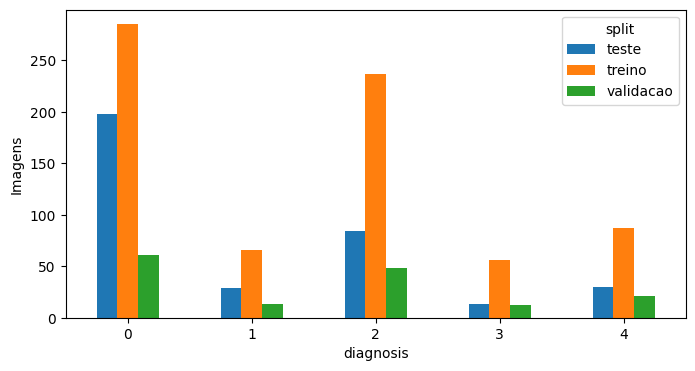

In [ ]:
def separar_grupos(df,frac,seed):
    df=df.reset_index(drop=True)
    if df.grupo.nunique()<2: raise ValueError('Grupos insuficientes para dividir.')
    y=df.diagnosis.astype(int).to_numpy(); g=df.grupo.to_numpy()
    classes=np.bincount(y,minlength=5); alvo=classes*frac
    melhor=None
    for a,b in GroupShuffleSplit(n_splits=300,test_size=frac,random_state=seed).split(df,y,g):
        cb=np.bincount(y[b],minlength=5); ca=classes-cb
        if np.any(cb[classes>0]==0) or np.any(ca[classes>0]==0): continue
        erro=np.mean(np.abs(cb-alvo)/np.maximum(alvo,1))+2*abs(len(b)/len(df)-frac)
        if melhor is None or erro<melhor[0]: melhor=(erro,a,b)
    if melhor is None: raise ValueError('Não foi possível representar todos os graus nas duas divisões sem separar grupos. Revise grupos/fracões.')
    return df.iloc[melhor[1]].copy(),df.iloc[melhor[2]].copy()
if MODO_SPLIT=='preservar_teste':
    dev=limpos[limpos.origem.ne('teste')].copy(); teste=limpos[limpos.origem.eq('teste')].copy()
    treino,val=separar_grupos(dev,FRACAO_VAL_DEV,SEED)
else:
    dev,teste=separar_grupos(limpos,.15,SEED)
    treino,val=separar_grupos(dev,.15/.85,SEED+1)
manifesto=pd.concat([treino.assign(split='treino'),val.assign(split='validacao'),teste.assign(split='teste')],ignore_index=True)
assert manifesto.uid.is_unique and manifesto.grupo.groupby(manifesto.grupo).size().sum()==len(manifesto)
assert manifesto.groupby('grupo').split.nunique().max()==1
for col in ['sha_arquivo','sha_pixels']:
    assert manifesto.groupby(col).split.nunique().max()==1
assert set(manifesto.loc[manifesto.split.eq('treino'),'diagnosis'])==set(range(5)), 'Treino sem todos os cinco graus.'
assert set(manifesto.loc[manifesto.split.eq('validacao'),'diagnosis'])==set(range(5)), 'Validação sem todos os cinco graus.'
assert len(teste)>0,'Teste vazio após curadoria.'
if MODO_SPLIT=='preservar_teste': assert manifesto.loc[manifesto.split.eq('teste'),'origem'].eq('teste').all()
manifesto.to_csv(RELATORIOS/'manifesto_split.csv',index=False)
print(manifesto.split.value_counts()); display(pd.crosstab(manifesto.diagnosis,manifesto.split))
pd.crosstab(manifesto.diagnosis,manifesto.split).plot.bar(rot=0,figsize=(8,4),ylabel='Imagens'); plt.show()

## 10. Correção fotométrica: CLAHE moderado no canal L do LAB
O CLAHE divide a luminância em regiões e limita a amplificação do histograma local. Mantemos os canais cromáticos A/B e misturamos 50% do L original com 50% do L realçado. É uma adaptação conservadora do CLAHE descrito no levantamento e no notebook de referência. O CLAHE não recupera pixels saturados ou estruturas encobertas. A conversão LAB/RGB de 8 bits pode alterar discretamente as cores.

Para que o fundo não domine o histograma, preenchemos temporariamente os pixels externos à máscara com o valor do pixel interno mais próximo, usando a transformada de distância. A imagem auxiliar serve somente ao cálculo de CLAHE; a saída restaura o fundo original. A grade 8×8 e o limite 2 são iniciais, e a mistura reduz exageros. Em FOV incerto, não aplicamos realce, para não amplificar uma região errada. O filtro bilateral opcional suaviza dentro do campo sem misturar livremente intensidades distintas, mas pode eliminar lesões pequenas; fica desligado por padrão. Não aplicamos Canny/B-COSFIRE/Top-hat como substitutos da imagem RGB, nem empilhamos vários realces.

A alternativa `REALCE='none'` produz o controle geométrico. Compare os métodos na validação, mantendo o mesmo split e arquitetura. Não use o teste para escolher parâmetros.

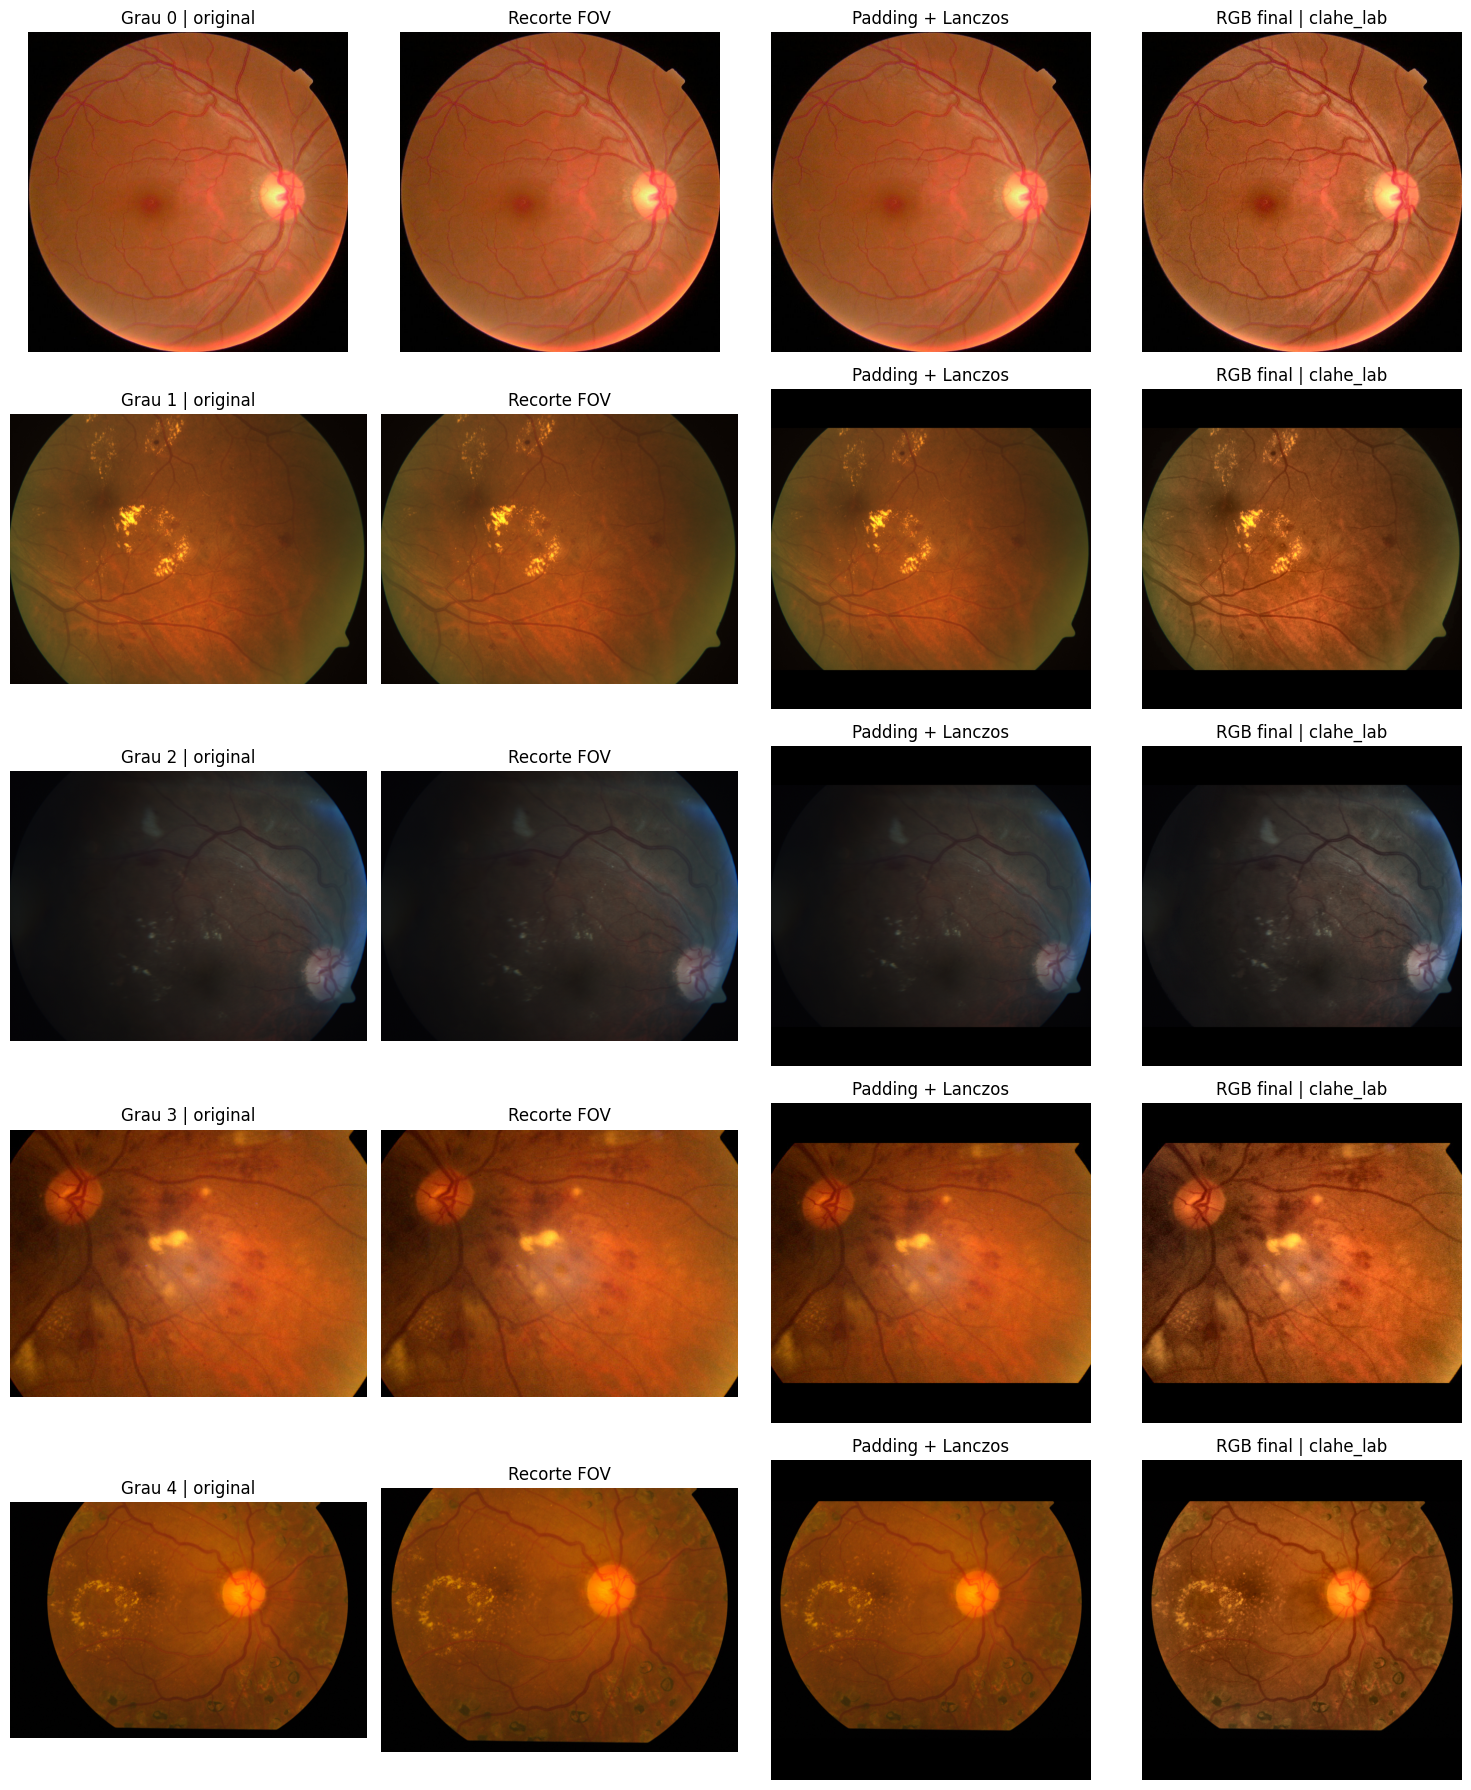

In [ ]:
def realcar(rgb,mask,incerto):
    if REALCE=='none' or incerto or mask.sum()<100: return rgb.copy()
    lab=cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB)
    l=lab[:,:,0].copy()
    # Prolongamento temporário de luminância; não modifica a anatomia na saída.
    inds=distance_transform_edt(~mask,return_distances=False,return_indices=True)
    preenchido=l[tuple(inds)]
    if DENOISE:
        preenchido=cv2.bilateralFilter(preenchido,5,12,12)
    eq=cv2.createCLAHE(clipLimit=CLAHE_CLIP,tileGridSize=CLAHE_GRID).apply(preenchido)
    lnovo=np.rint((1-CLAHE_MISTURA)*preenchido.astype(np.float32)+CLAHE_MISTURA*eq).clip(0,255).astype(np.uint8)
    lab[:,:,0]=np.where(mask,lnovo,l)
    out=cv2.cvtColor(lab,cv2.COLOR_LAB2RGB); out[~mask]=rgb[~mask]
    return out

def preprocessar(caminho):
    original=carregar_rgb(caminho)
    geo,mask,info=geometria(original,IMG_SIZE)
    final=realcar(geo,mask,info['incerto'])
    assert final.shape==(IMG_SIZE,IMG_SIZE,3) and final.dtype==np.uint8
    return original,geo,final,mask,info

# Comparação visual com exemplos já atribuídos ao treino.
exemplos=manifesto[manifesto.split.eq('treino')].groupby('diagnosis',group_keys=False).sample(n=1,random_state=SEED)
fig,axs=plt.subplots(len(exemplos),4,figsize=(15,3.6*len(exemplos)),squeeze=False)
for i,r in enumerate(exemplos.itertuples(index=False)):
    original,geo,final,mask,info=preprocessar(r.caminho)
    x0,y0,x1,y1=info['caixa']; rec=original[y0:y1,x0:x1]
    for ax,im,t in zip(axs[i],[original,rec,geo,final],[f'Grau {int(r.diagnosis)} | original','Recorte FOV','Padding + Lanczos',f'RGB final | {REALCE}']):
        ax.imshow(im); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show(); plt.close(fig)

## 11. Processamento de todo o conjunto e exportação sem perdas
Cada imagem é processada uma vez, sob demanda de um laço que mantém uma imagem em memória. Os PNGs RGB de 8 bits são gravados no disco local e validados por decodificação. O manifesto contém caminhos relativos, grau, grupo e origem. Os indicadores registram escala geométrica, deslocamento, máscara incerta e variação de saturação. Qualquer falha interrompe a liberação dos dados em vez de descartar silenciosamente a amostra.

O cache é separado por assinatura do manifesto e configuração. Em caso de mudança de recorte, resolução, realce ou decisões de curadoria, uma nova pasta será criada. O ZIP opcional será produzido ao fim, sem incluir os originais.

In [ ]:
config=dict(seed=SEED,tamanho=IMG_SIZE,limiar_fov=LIMIAR_FOV,margem_fov=MARGEM_FOV,realce=REALCE,clahe_clip=CLAHE_CLIP,clahe_grid=CLAHE_GRID,clahe_mistura=CLAHE_MISTURA,denoise=DENOISE,normalizacao=NORMALIZACAO,modo_split=MODO_SPLIT,phash_max=PHASH_MAX,foco_alerta=FOCO_ALERTA,area_alerta=AREA_ALERTA,exposicao_alerta=EXPOSICAO_ALERTA,qualidade_res=RES_QUALIDADE,min_lado=MIN_LADO,aug=AUGMENT,flip=FLIP,brilho=BRILHO,contraste=CONTRASTE)
assinatura=hashlib.sha256((json.dumps(config,sort_keys=True)+manifesto[['uid','sha_pixels','split','diagnosis','grupo']].to_csv(index=False)).encode()).hexdigest()[:16]
SAIDA=TRABALHO/f'processado_{assinatura}'; SAIDA.mkdir(exist_ok=True)
# Estimativa de pior caso (RGB sem compressão + margem); evita falta de disco.
necessario=len(manifesto)*IMG_SIZE*IMG_SIZE*3*1.10
if shutil.disk_usage(SAIDA).free < necessario:
    raise OSError('Espaço local possivelmente insuficiente para todos os PNGs; libere espaço antes de continuar.')
linhas=[]; falhas=[]
for r in tqdm(manifesto.itertuples(index=False),total=len(manifesto),desc='Processando e verificando PNGs'):
    try:
        original,geo,final,mask,info=preprocessar(r.caminho)
        relpath=Path(r.split)/f'{r.uid}.png'; destino=SAIDA/relpath; destino.parent.mkdir(exist_ok=True)
        tmp=destino.with_suffix('.tmp.png'); Image.fromarray(final).save(tmp,compress_level=3)
        if not np.array_equal(carregar_rgb(tmp),final): raise ValueError('PNG não preservou os pixels.')
        tmp.replace(destino)
        sat=lambda a: float((a[mask].max(axis=1)>=250).mean()) if mask.any() else np.nan
        linhas.append(dict(uid=r.uid,id_code=r.id_code,split=r.split,origem=r.origem,diagnosis=r.diagnosis,grupo=r.grupo,paciente=r.paciente,arquivo=relpath.as_posix(),sha_pixels_original=r.sha_pixels,sha_pixels_final=hashlib.sha256(final.tobytes()).hexdigest(),fov_incerto=info['incerto'],fov_pct=info['area']*100,deslocamento=info['desloc'],caixa=str(info['caixa']),padding=str(info['padding']),escala=IMG_SIZE/info['lado'],retencao_sinal=info['retencao'],sat_antes=sat(geo),sat_depois=sat(final)))
    except Exception as e: falhas.append(dict(uid=r.uid,erro=str(e)))
pd.DataFrame(falhas,columns=['uid','erro']).to_csv(RELATORIOS/'falhas_processamento.csv',index=False)
if falhas: raise RuntimeError(f'{len(falhas)} falhas. Corrija antes de continuar; veja falhas_processamento.csv.')
final_df=pd.DataFrame(linhas)
assert len(final_df)==len(manifesto)
# Uma colisão final entre splits pode ser criada pelo resize; interromper para investigar.
colisoes=final_df[final_df.sha_pixels_final.isin(final_df.groupby('sha_pixels_final').split.nunique().loc[lambda s:s>1].index)]
colisoes.to_csv(RELATORIOS/'colisoes_pos_processamento.csv',index=False)
if not colisoes.empty: raise ValueError('Pixels finais idênticos entre divisões. Revise o relatório antes de treinar.')
final_df.to_csv(SAIDA/'manifesto.csv',index=False)
final_df.to_csv(RELATORIOS/'manifesto_processado.csv',index=False)
display(final_df.groupby('split').agg(total=('uid','size'),fov_incerto=('fov_incerto','sum'),sat_antes=('sat_antes','mean'),sat_depois=('sat_depois','mean')))

Processando e verificando PNGs:   0%|          | 0/1240 [00:00<?, ?it/s]

,total,fov_incerto,sat_antes,sat_depois
split,,,,
teste,354,0,0.011569,0.012422
treino,731,0,0.009273,0.010615
validacao,155,0,0.014663,0.015108


## 12. Normalização e aumento de dados
A conversão RGB para float32 em [0,1] é comum a todos os métodos. `imagenet` usa as constantes de modelos PyTorch pré-treinados (ResNet/EfficientNet, quando a implementação espera essas constantes). `train` calcula média e desvio padrão por canal apenas com PNGs do treino, sem aumento; inclui o padding porque ele é parte do tensor de entrada. `zero_um` não aplica padronização adicional. Não normalize duas vezes: por exemplo, algumas EfficientNet do Keras incluem reescala interna.

O aumento é feito em memória, somente no treino. Inversão horizontal é admissível para graduação de RD sem informação de lateralidade; desligue para tarefas dependentes do olho. Brilho e contraste variam até 8%, conservando fundo preto quando o pixel é preto. Não usamos cortes, perspectiva, deformação elástica ou MixUp por padrão, pois podem modificar estruturas e rótulos. Validação e teste são determinísticos. A normalização não elimina, por si só, diferenças entre sensores.

In [ ]:
def estatisticas_treino(df):
    soma=np.zeros(3,np.float64); soma2=np.zeros(3,np.float64); n=0
    for r in tqdm(df[df.split.eq('treino')].itertuples(index=False),desc='Estatísticas somente do treino'):
        a=carregar_rgb(SAIDA/r.arquivo).reshape(-1,3).astype(np.float64)/255
        soma+=a.sum(axis=0); soma2+=(a*a).sum(axis=0); n+=len(a)
    if not n: raise ValueError('Treino vazio.')
    m=soma/n; s=np.sqrt(np.maximum(soma2/n-m*m,0))
    if np.any(s<1e-6): raise ValueError('Canal com desvio padrão nulo.')
    return m.tolist(),s.tolist()
if NORMALIZACAO=='train': MEDIA,DESVIO=estatisticas_treino(final_df)
elif NORMALIZACAO=='imagenet': MEDIA,DESVIO=[.485,.456,.406],[.229,.224,.225]
else: MEDIA,DESVIO=[0,0,0],[1,1,1]
config.update(media=MEDIA,desvio=DESVIO)
(SAIDA/'config.json').write_text(json.dumps(config,indent=2,ensure_ascii=False))
print('Média:',MEDIA,'| Desvio:',DESVIO)

def aumentar(a):
    if FLIP and torch.rand(()).item()<.5: a=np.ascontiguousarray(a[:,::-1])
    b=1+(2*torch.rand(()).item()-1)*BRILHO
    k=1+(2*torch.rand(()).item()-1)*CONTRASTE
    # Contraste em torno da média da região não preta; fundo original não muda.
    mask=a.max(axis=2)>0; out=a.astype(np.float32)
    if mask.any():
        centro=out[mask].mean(axis=0); out[mask]=((out[mask]-centro)*k+centro)*b
    return np.rint(out).clip(0,255).astype(np.uint8)

def tensorizar(a):
    x=a.astype(np.float32)/255
    x=(x-np.asarray(MEDIA,np.float32))/np.asarray(DESVIO,np.float32)
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2,0,1)))

class RetinaDataset(Dataset):
    def __init__(self,df,treinar=False): self.df=df.reset_index(drop=True); self.treinar=treinar
    def __len__(self): return len(self.df)
    def __getitem__(self,i):
        r=self.df.iloc[i]; a=carregar_rgb(SAIDA/r.arquivo)
        if self.treinar and AUGMENT: a=aumentar(a)
        # -1 representa teste sem rótulo; nunca forneça esses alvos à loss.
        y=-1 if pd.isna(r.diagnosis) else int(r.diagnosis)
        return tensorizar(a),torch.tensor(y,dtype=torch.long),r.uid

def criar_loader(split):
    ds=RetinaDataset(final_df[final_df.split.eq(split)],treinar=split=='treino')
    return DataLoader(ds,batch_size=BATCH_SIZE,shuffle=split=='treino',num_workers=NUM_WORKERS,generator=torch.Generator().manual_seed(SEED))
train_loader=criar_loader('treino'); val_loader=criar_loader('validacao'); test_loader=criar_loader('teste')
# Inferência sobre uma imagem externa: mesma transformação determinística.
def preparar_inferencia(caminho):
    _,_,a,_,info=preprocessar(caminho)
    return tensorizar(a).unsqueeze(0),info


Média: [0.485, 0.456, 0.406] | Desvio: [0.229, 0.224, 0.225]


## 13. Testes de aceitação antes de treinar
O teste percorre todos os lotes sem augmentation para verificar forma, tipo, valores finitos, rótulos, unicidade e cobertura. Também verifica o carregador de treinamento com aumento habilitado e a determinância da validação. Uma CNN de teste, sem treinamento, verifica se o formato é compatível com cinco logits e CrossEntropyLoss. O código não declara que o dataset está livre de toda duplicata perceptual ou que as imagens são clinicamente graduáveis. A aprovação é técnica, não diagnóstica. A CNN deve receber `float32` na forma N×3×H×W e rótulos `long` para `CrossEntropyLoss` com cinco saídas. O identificador é o terceiro elemento do lote. Teste sem rótulo usa -1 apenas para inferência.

In [ ]:
for split in ['treino','validacao','teste']:
    ds=RetinaDataset(final_df[final_df.split.eq(split)],treinar=False)
    loader=DataLoader(ds,batch_size=BATCH_SIZE,num_workers=NUM_WORKERS,shuffle=False)
    vistos=set()
    for x,y,ids in tqdm(loader,desc=f'Teste integral: {split}'):
        assert x.ndim==4 and tuple(x.shape[1:])==(3,IMG_SIZE,IMG_SIZE)
        assert x.dtype==torch.float32 and torch.isfinite(x).all()
        assert y.dtype==torch.long and ((y>=(-1 if split=='teste' else 0))&(y<=4)).all()
        assert not vistos.intersection(ids); vistos.update(ids)
    assert len(vistos)==len(ds)
    assert len(ds)>0
    x1,y1,_=ds[0]; x2,y2,_=ds[0]; assert torch.equal(x1,x2) and torch.equal(y1,y2)
x,y,ids=next(iter(train_loader)); assert torch.isfinite(x).all() and (y>=0).all()
print('Lote treino:',tuple(x.shape),y.tolist())
# Smoke test de compatibilidade, sem treinamento ou alegação de desempenho.
cnn_teste=torch.nn.Sequential(torch.nn.Conv2d(3,8,kernel_size=5,stride=4,padding=2),torch.nn.ReLU(),torch.nn.AdaptiveAvgPool2d(1),torch.nn.Flatten(),torch.nn.Linear(8,5))
with torch.no_grad():
    logits=cnn_teste(x); loss=torch.nn.CrossEntropyLoss()(logits,y)
    assert logits.shape==(len(y),5) and torch.isfinite(loss)
print('Compatibilidade CNN + CrossEntropyLoss:',tuple(logits.shape),'| loss finita:',float(loss))
assert final_df.retencao_sinal.ge(.995).all(), 'Retenção inferior ao mínimo técnico; revise imagens.'
assert final_df.groupby('grupo').split.nunique().max()==1
assert final_df.groupby('sha_pixels_original').split.nunique().max()==1
assert final_df.groupby('sha_pixels_final').split.nunique().max()==1
print('APROVADO nos testes técnicos implementados. Revisão clínica e validação experimental continuam necessárias.')
# Pesos para loss opcional, calculados só no treino. Não alteram a distribuição do teste.
contagens=final_df[final_df.split.eq('treino')].diagnosis.value_counts().reindex(range(5),fill_value=0).sort_index()
class_weights=torch.tensor(contagens.sum()/(5*contagens.to_numpy()),dtype=torch.float32)
print('Pesos opcionais (graus 0–4):',class_weights.tolist())

Teste integral: treino:   0%|          | 0/183 [00:00<?, ?it/s]

Teste integral: validacao:   0%|          | 0/39 [00:00<?, ?it/s]

Teste integral: teste:   0%|          | 0/89 [00:00<?, ?it/s]

Lote treino: (4, 3, 768, 768) [0, 2, 1, 2]
Compatibilidade CNN + CrossEntropyLoss: (4, 5) | loss finita: 1.6026971340179443
APROVADO nos testes técnicos implementados. Revisão clínica e validação experimental continuam necessárias.
Pesos opcionais (graus 0–4): [0.5129824280738831, 2.21515154838562, 0.6168776154518127, 2.6107141971588135, 1.68045973777771]


## 14. Entrega e uso posterior
Os dados processados estão em `SAIDA`. O manifesto, a configuração e os relatórios possibilitam repetir o procedimento e reconstruir os splits. O ZIP opcional contém os PNGs e os relatórios, mas não os arquivos originais. A exportação não inclui imagens aumentadas; elas são geradas somente no treino. Ajuste o caminho de saída se desejar. Os relatórios contêm caminhos e identificadores de pesquisa; compartilhe apenas se a licença e as normas de privacidade permitirem.

In [ ]:
if EXPORTAR_ZIP:
    destino=RELATORIOS/f'APTOS_CNN_{assinatura}.zip'
    temporario=TRABALHO/f'APTOS_CNN_{assinatura}.zip'
    with zipfile.ZipFile(temporario,'w',compression=zipfile.ZIP_STORED,allowZip64=True) as z:
        for p in tqdm(sorted(SAIDA.rglob('*')),desc='Exportando PNGs'):
            if p.is_file(): z.write(p,p.relative_to(SAIDA).as_posix())
        for p in sorted(RELATORIOS.glob('*.csv')): z.write(p,'auditoria/'+p.name)
    shutil.copyfile(temporario,destino)
    print('ZIP:',destino)
else: print('Imagens em:',SAIDA,'| Para exportar, altere EXPORTAR_ZIP=True e execute esta célula.')

## 15. Justificativa científica, limites e próximos experimentos
| Fonte | Aplicação no notebook | Limite |
|---|---|---|
| Men et al. (2025), DRStageNet, [DOI](https://doi.org/10.1088/1361-6579/ada86a) | Preservação geométrica e preparação de imagens em resolução alta | FOV, Lanczos e 768 px são escolhas próprias, não reprodução do artigo |
| Ghadai et al. (2026), [DOI](https://doi.org/10.1186/s12886-026-04897-4) | CLAHE, comparação com/sem CLAHE; configuração LAB-L do notebook OIO-MAIS | Mistura 50%, tratamento da máscara e resolução são adaptações |
| Anupama et al., [DOI](https://doi.org/10.1038/s41598-025-31339-w) | Motivação para realce local e comparação de métodos fotométricos | Adaptive Sigmoid e LAB-ACE não foram reproduzidos; não devem ser confundidos com CLAHE |
| Fu et al. (2019), [EyeQ](https://github.com/HzFu/EyeQ); QuickQual, [DOI](https://doi.org/10.1007/978-3-031-44013-7_4) | Importância de distinguir qualidade de diagnóstico | Laplaciano/FOV/exposição são indicadores próprios, não o classificador EyeQ |
| Shain e Daniel, [DOI](https://doi.org/10.1016/j.bspc.2026.111406) | Filtragem de qualidade e separação por paciente segundo levantamento fornecido | Não reproduz arquitetura ou filtro EyeQ |
| Tang, [preprint](https://arxiv.org/abs/2610.29104) | Motivação para controle de diferenças entre câmeras e resolução | Evidência preliminar; padronização não elimina mudança de domínio |
| Guidoum et al. (2026), EdgeRetina, [DOI](https://doi.org/10.11591/ijra.v15i1.pp234-246), PDF enviado, seção 2 e tabela 1 | Aumento conservador e normalização | Não adotamos 128 px nem agrupamos os graus |
| Gandor et al., [DOI](https://doi.org/10.1038/s41598-025-06973-z); Deepsahith et al., [DOI](https://doi.org/10.3389/frai.2025.1731633) | Realce vascular como alternativa para características adicionais | B-COSFIRE, Canny e Top-hat não substituem o RGB |
| [Revisão sobre qualidade de retinografias](https://pmc.ncbi.nlm.nih.gov/articles/PMC10858054/) | Revisão de qualidade, foco e viés de seleção | Métricas heurísticas precisam de avaliação clínica |

**Fontes locais:** `levantamento_tecnicas_e_modelos.xlsx` (linhas 2–23), `edge.pdf` (seção 2), `Tratamento_Imagens.ipynb` e `DRStageNet_APTOS_Preprocessamento_Colab.ipynb`. O catálogo de artigos não contém detalhes completos de todos os métodos; as decisões próprias estão explicitadas nas seções. Nenhuma métrica de classificação foi medida aqui.

**Experimento recomendado:** manter o mesmo manifesto e comparar geometria sem CLAHE vs. CLAHE moderado, 518 vs. 768 pixels e aumento desativado vs. ativado. Escolher pela validação (macro-F1, QWK, sensibilidade por grau), congelar a configuração e só então avaliar o teste. Verificar desempenho por qualidade e câmera quando disponível. O APTOS não oferece máscaras de lesões para cada imagem; não se pode garantir preservação de microaneurismas apenas por métricas globais. Avaliar em IDRiD com máscaras ou revisão especializada. O notebook não garante zero erros futuros, ausência de vazamento por pacientes desconhecidos ou superioridade clínica.